In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
data = {
    'Hours_Studied': [2,3,4,5,6,7,8,9,10,11,12,13,14,15,16],
    'Marks': [35,38,42,45,49,52,56,60,63,67,70,74,78,81,85]
}

df = pd.DataFrame(data)

print(df)

    Hours_Studied  Marks
0               2     35
1               3     38
2               4     42
3               5     45
4               6     49
5               7     52
6               8     56
7               9     60
8              10     63
9              11     67
10             12     70
11             13     74
12             14     78
13             15     81
14             16     85


In [3]:
X = df[['Hours_Studied']]
y = df['Marks']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 10
Testing samples: 5


In [5]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 27.25749559082892
Coefficient: 3.602586713697826


In [6]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred
})

print(comparison)

   Actual Marks  Predicted Marks
0            67        66.885949
1            74        74.091123
2            35        34.462669
3            81        81.296296
4            52        52.475603


In [7]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

MSE: 0.12480496135862498
RMSE: 0.3532774566238624
MAE: 0.30288065843621725
R2 Score: 0.9995407530123689


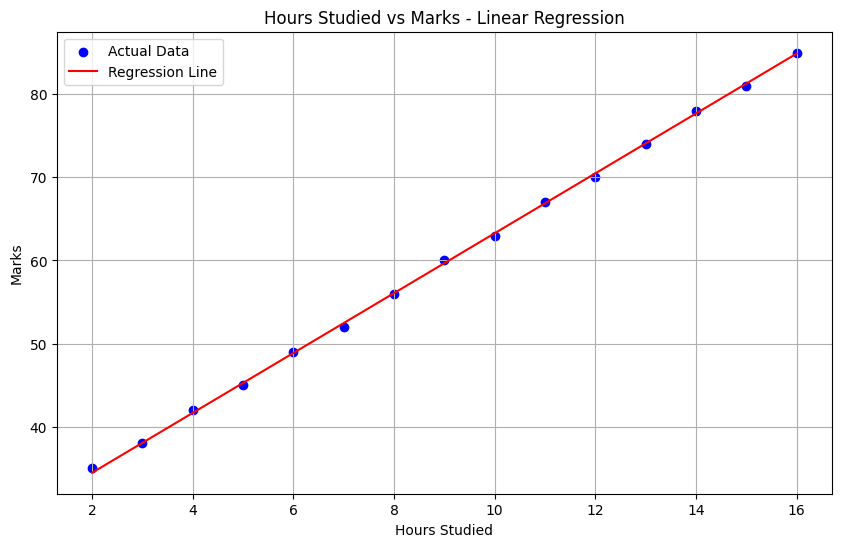

In [8]:
plt.figure(figsize=(10,6))

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.xlabel('Hours Studied')
plt.ylabel('Marks')

plt.title('Hours Studied vs Marks - Linear Regression')

plt.legend()
plt.grid()
plt.show()

In [9]:
new_data = pd.DataFrame({
    'Hours_Studied': [5, 10, 12, 18]
})

predictions = model.predict(new_data)

result = pd.DataFrame({
    'Hours Studied': new_data['Hours_Studied'],
    'Predicted Marks': predictions
})

print(result)

   Hours Studied  Predicted Marks
0              5        45.270429
1             10        63.283363
2             12        70.488536
3             18        92.104056


In [10]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("TRAINING PERFORMANCE")
print("Training MSE:",
      mean_squared_error(y_train, train_pred))
print("Training R2:",
      r2_score(y_train, train_pred))

print("\nTESTING PERFORMANCE")
print("Testing MSE:",
      mean_squared_error(y_test, test_pred))
print("Testing R2:",
      r2_score(y_test, test_pred))

TRAINING PERFORMANCE
Training MSE: 0.07348618459729549
Training R2: 0.9996672424171468

TESTING PERFORMANCE
Testing MSE: 0.12480496135862498
Testing R2: 0.9995407530123689
